# Estatísticas de segurança do estado do Rio de Janeiro (2014–2026): notebook de análise exploratória

**Autoria:** [FABIANO BASTOS] · Bacharelado em Sistemas de Informação, UniLaSalle · 6º período
**Disciplina:** Linguagem de Programação (Análise e Visualização de Dados com Python) · **Semestre:** 2026.2
**Fonte dos dados:** Instituto de Segurança Pública do Estado do Rio de Janeiro (ISP-RJ), portal ISPDados: <https://www.ispdados.rj.gov.br/>

Este notebook documenta a exploração, a validação e a prototipação das análises que sustentam o artigo em `docs/index.html`. A limpeza e as métricas ficam em módulos reutilizáveis (`src/etl.py` e `src/analise.py`); o notebook os **chama e mostra o resultado**, de modo que texto, figuras e artigo usam exatamente os mesmos números.

### Perguntas de pesquisa

- **RQ1.** Como evoluiu a letalidade violenta no estado entre 2014 e 2026, e qual a participação das mortes por intervenção de agente do Estado nela?
- **RQ2.** Roubos e furtos seguiram trajetórias diferentes, e como reagiram à pandemia de 2020?
- **RQ3.** Quão concentrada geograficamente é a criminalidade e o perfil das ocorrências difere entre as regiões?

> **Cuidado de leitura:** os números são **contagens absolutas**, sem normalização por população. Comparações entre municípios refletem, em boa parte, o tamanho de cada um.

In [1]:
import sys
from pathlib import Path
import io
from IPython.display import Image, Markdown, display
import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import etl, analise

pd.set_option("display.max_columns", 30, "display.width", 140)
ASSETS = RAIZ / "docs" / "assets"

def mostrar(fig):
    # Exibe a figura como PNG (as funções de src/analise.py usam o backend Agg)
    buf = io.BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight", facecolor="white")
    display(Image(data=buf.getvalue()))
    plt.close(fig)

## 1. Leitura da base bruta

In [2]:
raw = etl.ler_base_bruta()
print(f"Linhas: {len(raw):,} | Colunas: {raw.shape[1]}".replace(",", "."))
print(f"Arquivo: {etl.ARQUIVO_BRUTO.name} | separador '{etl.SEPARADOR}' | codificação {etl.CODIFICACAO}")
raw.iloc[:4, :12]

Linhas: 14.076 | Colunas: 62
Arquivo: BaseMunicipioMensal.csv | separador ';' | codificação latin-1


,fmun_cod,fmun,ano,mes,mes_ano,regiao,hom_doloso,lesao_corp_morte,latrocinio,cvli,hom_por_interv_policial,feminicidio
0,3300100,Angra dos Reis,2014,1,2014m01,Interior,11,0,0,11,1,NaN
1,3300159,Aperibé,2014,1,2014m01,Interior,0,0,0,0,0,NaN
2,3300209,Araruama,2014,1,2014m01,Interior,2,0,0,2,0,NaN
3,3300225,Areal,2014,1,2014m01,Interior,0,0,0,0,0,NaN


O arquivo usa `;` como separador e codificação Latin-1. Lido com UTF-8, os nomes de municípios com acento quebrariam. A unidade de observação é o par **município × mês** (92 municípios, jan/2014 a set/2026).

## 2. Validações de qualidade

In [3]:
verif = etl.validar_esquema(raw)
for k, v in verif.items():
    print(f"{k:20s}: {v}")
nulos = raw.isna().sum()
print("\nColunas com nulos:")
print(nulos[nulos > 0].to_string())

colunas_extras      : []
chaves_duplicadas   : 0
municipios          : 92
painel_balanceado   : True
linhas_por_mes      : 92
periodo             : ['2014m01', '2026m09']

Colunas com nulos:
feminicidio              11868
tentativa_feminicidio    11868


Só `feminicidio` e `tentativa_feminicidio` têm ausências, e elas seguem um padrão exato: a série **só existe a partir de outubro de 2024**. Antes disso o valor é inexistente, e não zero. Imputar zero criaria um falso "não houve feminicídio" em 129 meses. O ETL mantém o valor como `NA`.

In [4]:
com_fem = raw["feminicidio"].notna()
print("Primeiro mês com feminicídio:", raw.loc[com_fem, "mes_ano"].iloc[0], "| meses sem a série:", raw.loc[~com_fem, "mes_ano"].nunique())

# identidades internas da base
cvli_ok = (raw["cvli"] == raw["hom_doloso"] + raw["lesao_corp_morte"] + raw["latrocinio"]).mean()
letal_antes = (raw.loc[~com_fem, "letalidade_violenta"] == raw.loc[~com_fem, "cvli"] + raw.loc[~com_fem, "hom_por_interv_policial"]).mean()
letal_depois = (raw.loc[com_fem, "letalidade_violenta"] == raw.loc[com_fem, "cvli"] + raw.loc[com_fem, "hom_por_interv_policial"] + raw.loc[com_fem, "feminicidio"]).mean()
rua_ok = (raw["roubo_rua"] == raw["roubo_transeunte"] + raw["roubo_celular"] + raw["roubo_em_coletivo"]).mean()
pd.Series({
    "cvli = hom_doloso + lesao_corp_morte + latrocinio": cvli_ok,
    "letalidade = cvli + interv. policial (antes de out/2024)": letal_antes,
    "letalidade = cvli + interv. policial + feminicidio (desde out/2024)": letal_depois,
    "roubo_rua = transeunte + celular + coletivo": rua_ok,
}).map("{:.0%}".format).to_frame("linhas que satisfazem")

Primeiro mês com feminicídio: 2024m10 | meses sem a série: 129


,linhas que satisfazem
cvli = hom_doloso + lesao_corp_morte + latrocinio,100%
letalidade = cvli + interv. policial (antes de out/2024),100%
letalidade = cvli + interv. policial + feminicidio (desde out/2024),100%
roubo_rua = transeunte + celular + coletivo,100%


**Achado 1: a definição de `letalidade_violenta` muda em out/2024.** Até setembro de 2024 ela é `cvli` + mortes por intervenção policial; a partir de outubro passa a somar também o feminicídio. Comparar a série bruta entre os dois períodos mistura duas definições. Por isso o ETL cria `letalidade_harmonizada` (= `cvli` + `hom_por_interv_policial`), que significa a mesma coisa em todos os meses, e é ela que usamos na RQ1.

In [5]:
# Totais de roubos e furtos x soma dos componentes
dif_r = (raw[etl.COMPONENTES_ROUBOS].sum(axis=1) - raw["total_roubos"])
dif_f = (raw[etl.COMPONENTES_FURTOS].sum(axis=1) - raw["total_furtos"])
inc = (dif_r != 0) | (dif_f != 0)
print(f"Linhas com divergência: {inc.sum()} ({inc.mean():.1%})")
print(f"Divergências exatamente espelhadas (dif. roubos = - dif. furtos): {int(((dif_r == -dif_f) & inc).sum())}")
resumo = (raw[inc].assign(dif_roubos=dif_r[inc], dif_furtos=dif_f[inc])
          .groupby("ano").agg(linhas=("fmun", "size"), dif_roubos=("dif_roubos", "sum"), dif_furtos=("dif_furtos", "sum")))
resumo

Linhas com divergência: 739 (5.3%)
Divergências exatamente espelhadas (dif. roubos = - dif. furtos): 707


,linhas,dif_roubos,dif_furtos
ano,,,
2014,167,3573,-3573
2015,189,2422,-2422
2016,131,3412,-3412
2017,110,1249,-1249
2018,104,1215,-1215
2021,6,-4,4
2025,31,0,562
2026,1,-1,0


**Achado 2: os totais de roubos e furtos nem sempre batem com a soma das partes.** São 739 linhas (5,2%), quase todas em 2014–2018. Em 707 delas a diferença de um total é exatamente o oposto da do outro, o que aponta **reclassificação entre roubo e furto**, e não erro aleatório. Não há como saber qual dos dois lados está certo, então o ETL **não corrige o dado original**: mantém os totais oficiais, cria colunas recalculadas (`*_recalc`) e flags (`inconsist_*`), e a seção 6 mede se isso muda as conclusões.

## 3. Tratamento (ETL)

In [6]:
tratado, log = etl.tratar(raw)
print(f"Linhas: {log['linhas_entrada']} -> {log['linhas_saida']} (removidas: {log['linhas_removidas']})")
print(f"Colunas: {log['colunas_entrada']} -> {log['colunas_saida']}")
print("Dados preliminares (fase 2):", log["linhas_dado_preliminar"])
print("Identidades verificadas:")
for k, v in log["identidades_verificadas"].items():
    print(f"  [{'ok' if v else 'FALHOU'}] {k}")
tratado[["fmun", "data", "regiao", "cvli", "feminicidio", "letalidade_harmonizada", "dado_preliminar"]].tail(3)

Linhas: 14076 -> 14076 (removidas: 0)
Colunas: 62 -> 70
Dados preliminares (fase 2): 276
Identidades verificadas:
  [ok] cvli = hom_doloso + lesao_corp_morte + latrocinio
  [ok] letalidade_violenta = cvli + interv. policial + feminicidio (desde out/2024)
  [ok] letalidade_violenta = cvli + interv. policial (antes de out/2024)
  [ok] roubo_rua = transeunte + celular + coletivo


,fmun,data,regiao,cvli,feminicidio,letalidade_harmonizada,dado_preliminar
14073,Varre-Sai,2026-09-01,Interior,1,0,1,True
14074,Vassouras,2026-09-01,Interior,0,0,0,True
14075,Volta Redonda,2026-09-01,Interior,1,0,1,True


In [7]:
# O arquivo salvo pelo pipeline (python -m src.etl) é idêntico ao tratamento refeito aqui?
df = etl.carregar_processado()
print("Idêntico ao arquivo processado:", tratado.reset_index(drop=True).equals(df.reset_index(drop=True)))
print("Tipos:", df.dtypes.astype(str).value_counts().to_dict())

Idêntico ao arquivo processado: True
Tipos: {'Int32': 58, 'int8': 3, 'bool': 3, 'str': 2, 'int32': 1, 'int16': 1, 'category': 1, 'datetime64[us]': 1}


O tratamento é **não destrutivo** (nenhuma linha removida, nenhum valor sobrescrito) e **determinístico**: refazê-lo produz exatamente o arquivo salvo. As decisões ficam em `data/processed/etl_log.json`.

## 4. Exploração geral

In [8]:
m = analise.calcular_metricas(df)
cols = ["hom_doloso", "letalidade_violenta", "total_roubos", "total_furtos", "registro_ocorrencias"]
desc = df[cols].astype("int64").describe(percentiles=[.5, .9, .99]).T.round(1)
desc["pct_zeros"] = (df[cols].astype("int64") == 0).mean().mul(100).round(1)
desc

,count,mean,std,min,50%,90%,99%,max,pct_zeros
hom_doloso,14076.0,3.5,10.9,0.0,1.0,8.0,63.2,146.0,48.0
letalidade_violenta,14076.0,4.6,15.6,0.0,1.0,10.0,94.0,247.0,46.2
total_roubos,14076.0,134.1,753.1,0.0,3.0,142.0,4407.2,12087.0,30.8
total_furtos,14076.0,143.9,847.6,0.0,17.0,152.0,5431.5,11863.0,5.2
registro_ocorrencias,14076.0,720.6,3451.3,0.0,123.0,957.5,24109.2,44545.0,2.8


A distribuição por município-mês é **extremamente assimétrica**: a mediana de registros é de poucas centenas, enquanto a capital passa de 30 mil por mês, e 48% das linhas têm zero homicídio. Médias simples entre municípios seriam enganosas, então a análise trabalha com **somas estaduais**, **participações** e **medidas de concentração** (Gini e curva de Lorenz).

## 5. Resultados

### RQ1 · Letalidade violenta e intervenção de agentes do Estado

In [9]:
ytd = m["ytd"][["cvli", "hom_por_interv_policial", "letalidade_harmonizada", "pct_interv"]].round(1)
ytd.columns = ["CVLI", "Mortes por interv. policial", "Letalidade harmonizada", "% interv. policial"]
ytd

,CVLI,Mortes por interv. policial,Letalidade harmonizada,% interv. policial
ano,,,,
2014,3958,438,4396,10.0
2015,3227,517,3744,13.8
2016,3849,636,4485,14.2
2017,4172,819,4991,16.4
2018,4027,1183,5210,22.7
2019,3157,1407,4564,30.8
2020,2749,935,3684,25.4
2021,2621,1097,3718,29.5
2022,2328,1017,3345,30.4


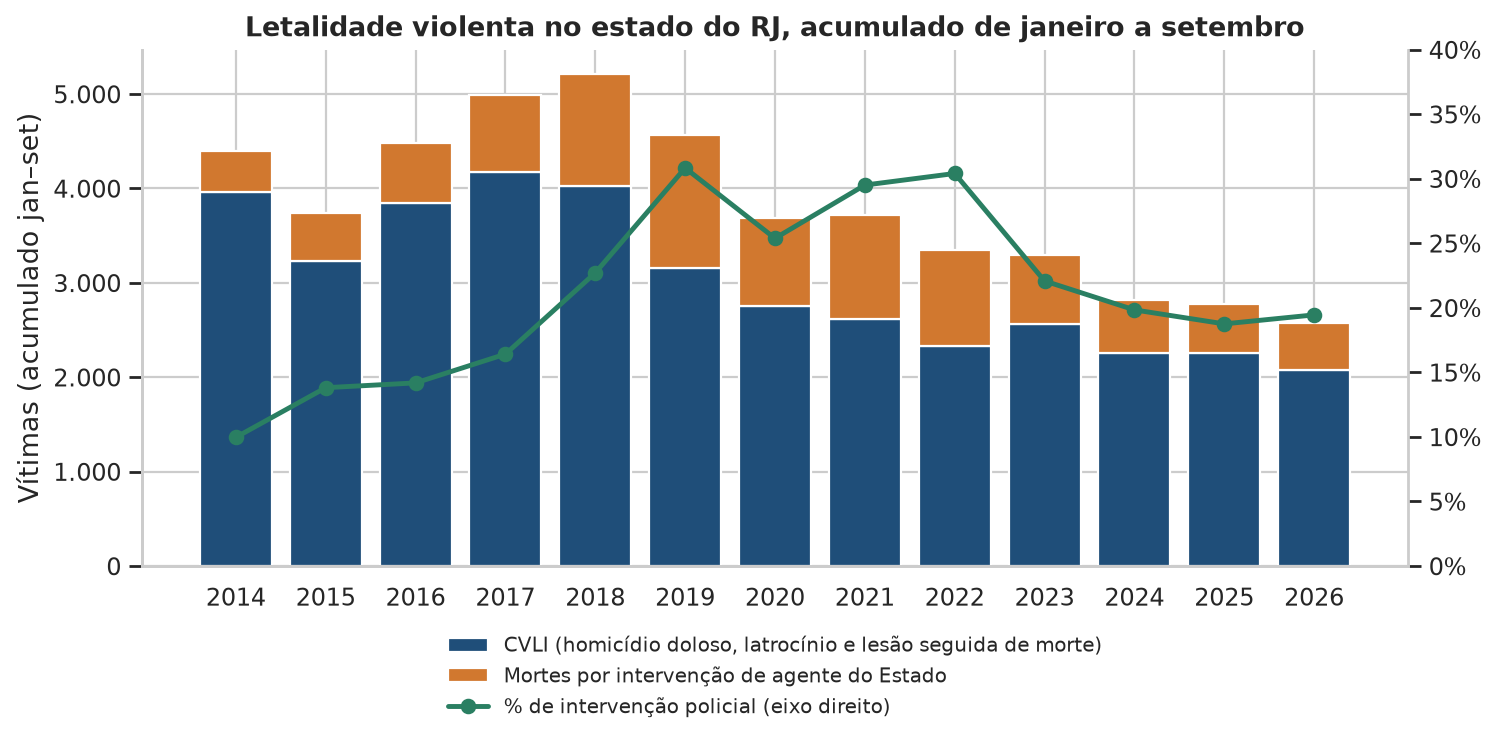

In [10]:
mostrar(analise.fig_letalidade_composicao(df, ASSETS / "fig1_letalidade_composicao.png"))

In [11]:
r = m["rq1"]; mes = analise.MESES_EXTENSO[m["mes_fim"] - 1]
display(Markdown(f"""
- Comparando **janeiro a {mes}** de cada ano, a letalidade harmonizada caiu de **{analise.milhar(r['let_ini'])}** ({m['a0']}) para **{analise.milhar(r['let_fim'])}** ({m['a1']}): variação de **{analise.pct_br(r['var_let'])}**. O pico foi em {r['pico_let_ano']} ({analise.milhar(r['pico_let'])}).
- O CVLI, sozinho, caiu {analise.pct_br(abs(r['var_cvli']))}. Já as mortes por intervenção de agente do Estado foram de {r['interv_ini']} para {r['interv_fim']}.
- Por isso a **participação das intervenções** na letalidade subiu de {analise.pct_br(r['pct_ini'])} ({m['a0']}) para um pico de **{analise.pct_br(r['pct_pico'])}** em {r['pct_pico_ano']}, e depois recuou para {analise.pct_br(r['pct_fim'])} em {m['a1']}.
- Em 2020 as intervenções caíram {analise.pct_br(abs(r['var_interv_2020']))} ({analise.milhar(r['interv_2019'])} → {analise.milhar(r['interv_2020'])}), no ano da liminar da ADPF 635 (5 de junho de 2020), que restringiu operações policiais em favelas durante a pandemia. A **coincidência temporal não prova causalidade**.
- Correlação de Spearman mensal (estado) entre CVLI e intervenções: **ρ = {analise.num_br(r['rho'])}** (p = {analise.num_br(r['p'], 3)}), isto é, associação **fraca**: as duas séries não andam juntas.
"""))


- Comparando **janeiro a setembro** de cada ano, a letalidade harmonizada caiu de **4.396** (2014) para **2.576** (2026): variação de **-41,4%**. O pico foi em 2018 (5.210).
- O CVLI, sozinho, caiu 47,6%. Já as mortes por intervenção de agente do Estado foram de 438 para 501.
- Por isso a **participação das intervenções** na letalidade subiu de 10,0% (2014) para um pico de **30,8%** em 2019, e depois recuou para 19,4% em 2026.
- Em 2020 as intervenções caíram 33,5% (1.407 → 935), no ano da liminar da ADPF 635 (5 de junho de 2020), que restringiu operações policiais em favelas durante a pandemia. A **coincidência temporal não prova causalidade**.
- Correlação de Spearman mensal (estado) entre CVLI e intervenções: **ρ = 0,19** (p = 0,016), isto é, associação **fraca**: as duas séries não andam juntas.


### RQ2 · Roubos e furtos

In [12]:
t = m["ytd"][["total_roubos", "total_furtos", "share_furto"]].round(1)
t.columns = ["Roubos", "Furtos", "% furtos no total"]
t

,Roubos,Furtos,% furtos no total
ano,,,
2014,119187,138830,53.8
2015,109570,136536,55.5
2016,149177,129025,46.4
2017,173843,108149,38.4
2018,176713,107199,37.8
2019,155387,117132,43.0
2020,93928,83802,47.2
2021,90592,82530,47.7
2022,80472,121883,60.2


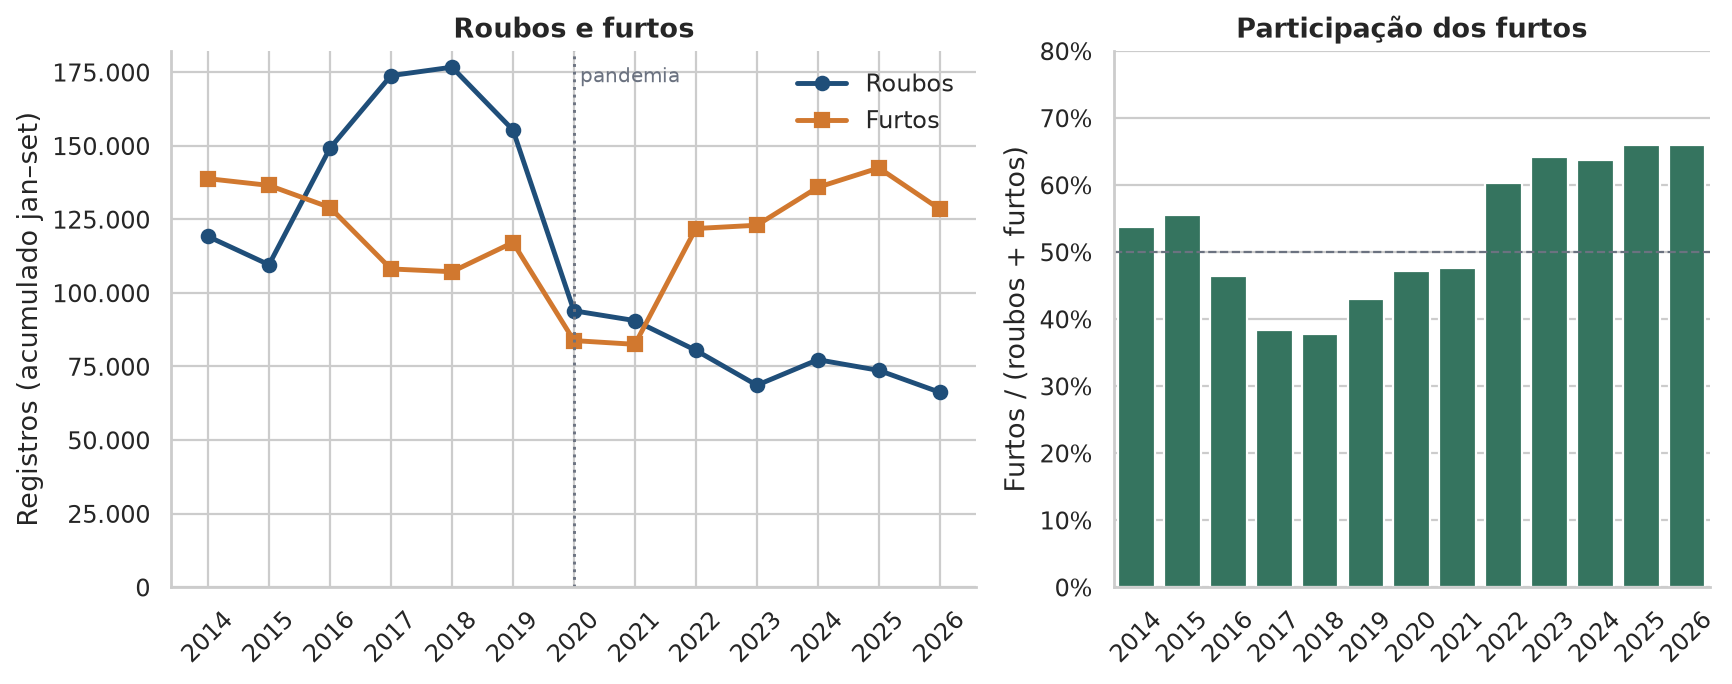

In [13]:
mostrar(analise.fig_roubos_furtos_anual(df, ASSETS / "fig2_roubos_furtos_anual.png"))

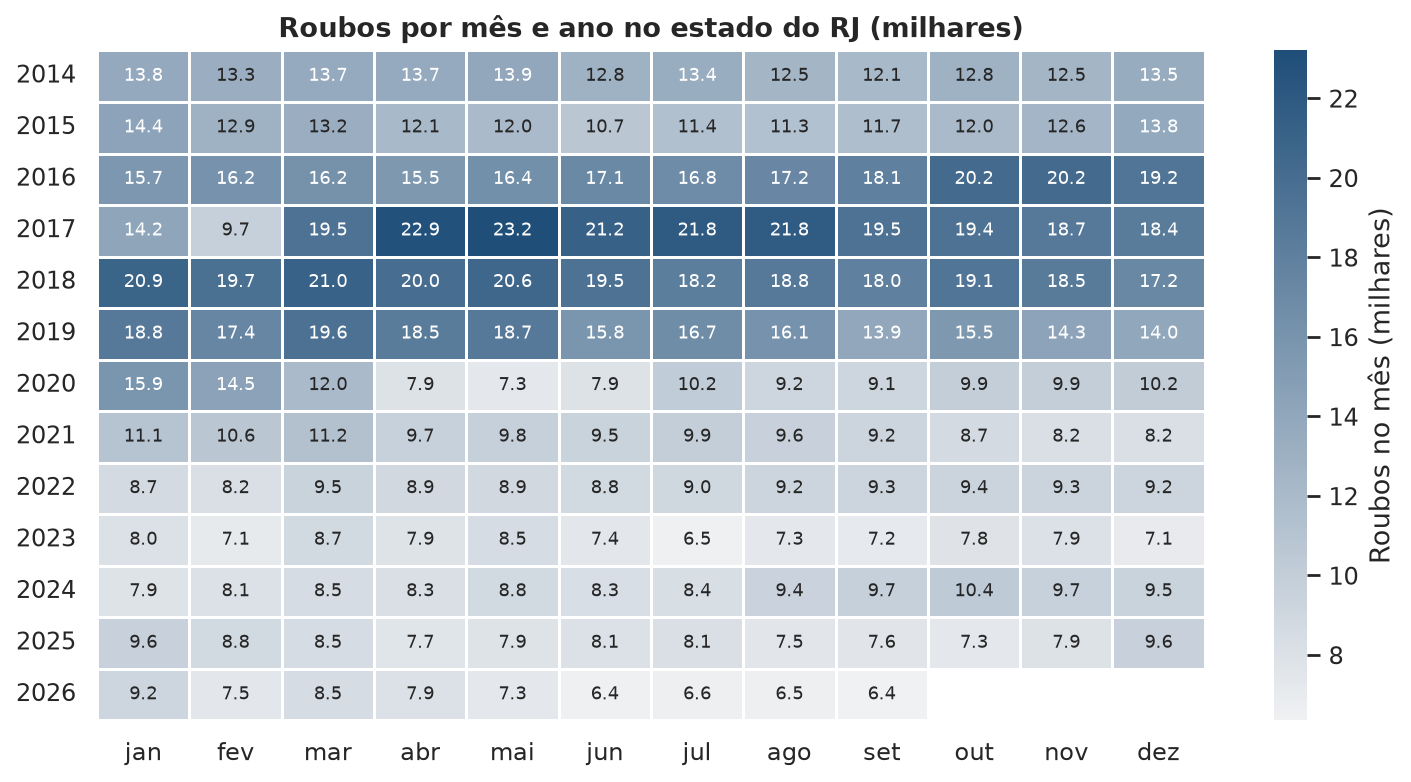

In [14]:
mostrar(analise.fig_sazonalidade_roubos(df, ASSETS / "fig3_sazonalidade_roubos.png"))

In [15]:
r = m["rq2"]
display(Markdown(f"""
- **Roubos:** pico anual em {r['pico_rou_ano']} ({analise.milhar(r['pico_rou'])}) e menor valor em {r['menor_rou_ano']} ({analise.milhar(r['menor_rou'])}), queda de **{analise.pct_br(abs(r['queda_rou']))}**. No acumulado de janeiro a {mes}, a queda entre {m['a0']} e {m['a1']} é de {analise.pct_br(abs(r['var_rou']))}.
- **Furtos:** variação de apenas {analise.pct_br(r['var_fur'])} no mesmo comparativo. Caíram entre 2014 e 2018, caíram de novo em 2020–2021 (pandemia) e **voltaram a subir** a partir de 2022.
- A participação dos furtos em (roubos + furtos) foi de {analise.pct_br(r['share_ini'])} em {m['a0']}, mínima de {analise.pct_br(r['share_min'])} em {r['share_min_ano']} e **{analise.pct_br(r['share_fim'])}** em {m['a1']}: o perfil patrimonial migrou de roubo para furto.
- **Pandemia:** em abril de 2020 houve {analise.milhar(r['abr_2020'])} roubos, **{analise.pct_br(r['razao_abr2020'] * 100, 0)}** da média mensal de 2019 ({analise.milhar(r['media_2019'])}).
- Correlação de Spearman mensal entre roubos e furtos: **ρ = {analise.num_br(r['rho'])}** (p = {analise.num_br(r['p'], 3)}), isto é, **fraca e negativa**: não se movem juntos.
"""))


- **Roubos:** pico anual em 2018 (231.606) e menor valor em 2023 (91.398), queda de **60,5%**. No acumulado de janeiro a setembro, a queda entre 2014 e 2026 é de 44,4%.
- **Furtos:** variação de apenas -7,5% no mesmo comparativo. Caíram entre 2014 e 2018, caíram de novo em 2020–2021 (pandemia) e **voltaram a subir** a partir de 2022.
- A participação dos furtos em (roubos + furtos) foi de 53,8% em 2014, mínima de 37,8% em 2018 e **66,0%** em 2026: o perfil patrimonial migrou de roubo para furto.
- **Pandemia:** em abril de 2020 houve 7.893 roubos, **48%** da média mensal de 2019 (16.610).
- Correlação de Spearman mensal entre roubos e furtos: **ρ = -0,21** (p = 0,011), isto é, **fraca e negativa**: não se movem juntos.


**Outlier temporal: fevereiro de 2017.** O mapa de calor mostra apenas 9,7 mil roubos nesse mês, contra 14,2 mil em janeiro e 19,5 mil em março. Furtos e total de registros caem junto (cerca de metade do mês seguinte), e a queda se concentra na capital. Não é efeito das divergências de classificação (o recálculo dá o mesmo valor). A queda simultânea em todas as categorias sugere **falha de registro ou de coleta**, e não queda real de criminalidade, mas **a base não permite confirmar a causa**. O ponto foi mantido e é citado como limitação.

In [16]:
fev = df[df["data"].between("2017-01-01", "2017-03-01")].groupby("data")[["total_roubos", "total_furtos", "registro_ocorrencias"]].sum().astype("int64")
fev.index = fev.index.strftime("%Y-%m")
fev

,total_roubos,total_furtos,registro_ocorrencias
data,,,
2017-01,14221,10074,51390
2017-02,9714,5795,31231
2017-03,19493,13620,60412


### RQ3 · Concentração geográfica e perfil regional

In [17]:
c = pd.DataFrame(m["rq3"]["conc"]).T
c.columns = ["Maior município (%)", "5 maiores (%)", "10 maiores (%)", "Gini", "Município líder"]
for col in ["Maior município (%)", "5 maiores (%)", "10 maiores (%)"]:
    c[col] = (c[col].astype(float) * 100).round(1)
c["Gini"] = c["Gini"].astype(float).round(3)
c.index = ["Homicídios dolosos", "Roubos", "Furtos", "Todos os registros"]
c

,Maior município (%),5 maiores (%),10 maiores (%),Gini,Município líder
Homicídios dolosos,28.3,53.7,67.4,0.775,Rio de Janeiro
Roubos,54.5,81.5,91.9,0.927,Rio de Janeiro
Furtos,60.4,74.8,81.5,0.865,Rio de Janeiro
Todos os registros,49.2,66.5,75.5,0.817,Rio de Janeiro


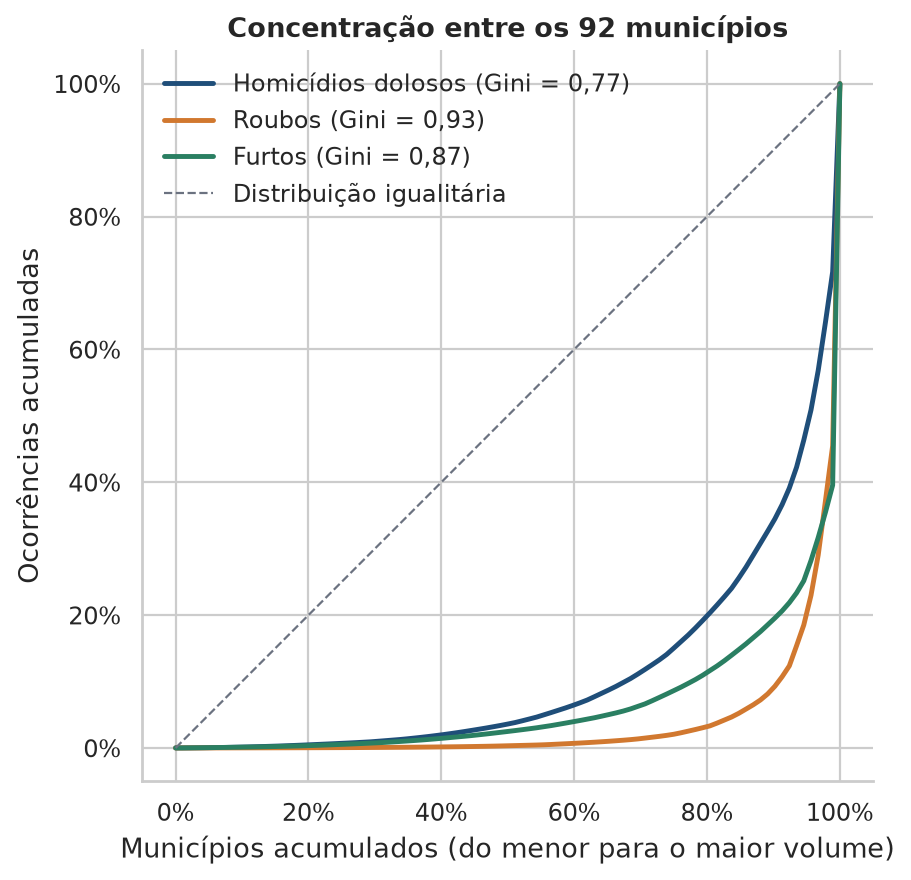

In [18]:
mostrar(analise.fig_lorenz(df, ASSETS / "fig4_lorenz.png"))

In [19]:
p = m["rq3"]["perfil"][["n_municipios", "pct_homicidios", "pct_roubos", "pct_furtos", "pct_registros", "roubos_por_homicidio"]].round(1)
p.columns = ["Municípios", "% homicídios", "% roubos", "% furtos", "% registros", "Roubos por homicídio"]
p

,Municípios,% homicídios,% roubos,% furtos,% registros,Roubos por homicídio
regiao,,,,,,
Capital,1,28.3,54.5,60.4,49.2,73.6
Grande Niterói,3,8.8,11.8,8.8,9.3,51.1
Baixada Fluminense,13,31.9,27.6,13.1,18.9,33.1
Interior,75,31.0,6.2,17.6,22.6,7.6


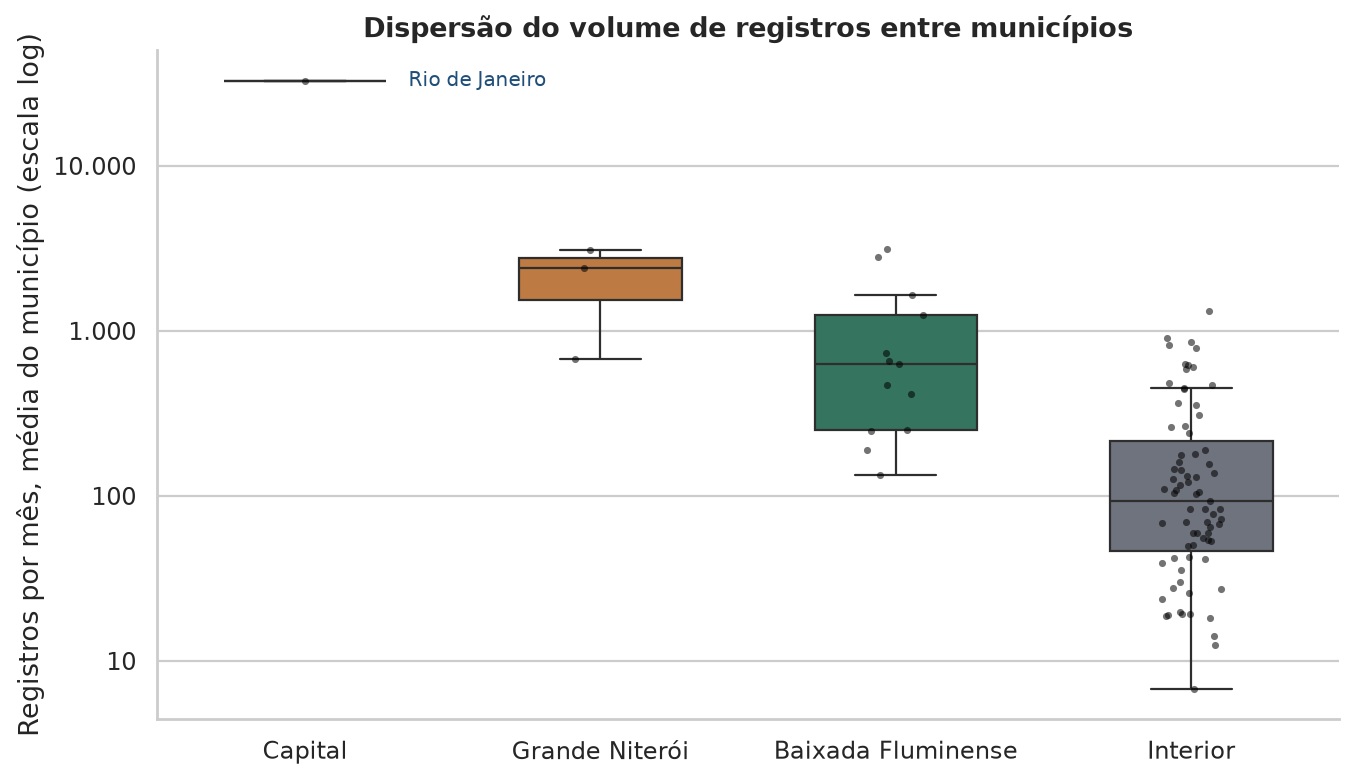

In [20]:
mostrar(analise.fig_boxplot_regioes(df, ASSETS / "fig5_boxplot_regioes.png"))

In [21]:
r3 = m["rq3"]; cc = r3["conc"]
display(Markdown(f"""
- Os **5 maiores municípios** concentram **{analise.pct_br(cc['hom_doloso']['top5'] * 100)}** dos homicídios dolosos, **{analise.pct_br(cc['total_roubos']['top5'] * 100)}** dos roubos e **{analise.pct_br(cc['total_furtos']['top5'] * 100)}** dos furtos. Gini: {analise.num_br(cc['hom_doloso']['gini'])} (homicídios), {analise.num_br(cc['total_furtos']['gini'])} (furtos) e {analise.num_br(cc['total_roubos']['gini'])} (roubos).
- A capital sozinha responde por {analise.pct_br(cc['total_roubos']['top1'] * 100)} dos roubos, mas por {analise.pct_br(cc['hom_doloso']['top1'] * 100)} dos homicídios.
- **O perfil muda por região:** são {r3['perfil'].loc['Capital', 'roubos_por_homicidio']:.0f} roubos por homicídio na Capital, {r3['perfil'].loc['Grande Niterói', 'roubos_por_homicidio']:.0f} em Grande Niterói, {r3['perfil'].loc['Baixada Fluminense', 'roubos_por_homicidio']:.0f} na Baixada e {analise.num_br(r3['perfil'].loc['Interior', 'roubos_por_homicidio'], 1)} no Interior. A Baixada e o Interior pesam mais nos homicídios do que nos crimes patrimoniais.
- Pelo critério do IQR sobre o volume mensal médio de registros (limite de {analise.milhar(r3['limite_iqr'])}), há **{len(r3['outliers'])} municípios atípicos**: {', '.join(r3['outliers'])}.
"""))


- Os **5 maiores municípios** concentram **53,7%** dos homicídios dolosos, **81,5%** dos roubos e **74,8%** dos furtos. Gini: 0,77 (homicídios), 0,87 (furtos) e 0,93 (roubos).
- A capital sozinha responde por 54,5% dos roubos, mas por 28,3% dos homicídios.
- **O perfil muda por região:** são 74 roubos por homicídio na Capital, 51 em Grande Niterói, 33 na Baixada e 7,6 no Interior. A Baixada e o Interior pesam mais nos homicídios do que nos crimes patrimoniais.
- Pelo critério do IQR sobre o volume mensal médio de registros (limite de 1.057), há **8 municípios atípicos**: Belford Roxo, Campos dos Goytacazes, Duque de Caxias, Niterói, Nova Iguaçu, Rio de Janeiro, São Gonçalo, São João de Meriti.


## 6. Teste de sensibilidade: o que muda se usarmos os totais recalculados?

In [22]:
r = m["rq2"]
anual = df.groupby("ano")[["total_roubos", "total_roubos_recalc", "total_furtos", "total_furtos_recalc"]].sum().astype("int64")
anual["dif_roubos_%"] = ((anual["total_roubos_recalc"] / anual["total_roubos"] - 1) * 100).round(2)
anual["dif_furtos_%"] = ((anual["total_furtos_recalc"] / anual["total_furtos"] - 1) * 100).round(2)
display(anual)
display(Markdown(f"""Usar a soma dos componentes em vez dos totais oficiais altera os totais anuais em **no máximo {analise.pct_br(r['dif_rou_max'])}** (roubos) e {analise.pct_br(r['dif_fur_max'])} (furtos). Pico, vale e a migração de roubo para furto **permanecem iguais**: as conclusões não dependem da escolha."""))

,total_roubos,total_roubos_recalc,total_furtos,total_furtos_recalc,dif_roubos_%,dif_furtos_%
ano,,,,,,
2014,157995,161568,182340,178767,2.26,-1.96
2015,147933,150355,179845,177423,1.64,-1.35
2016,208781,212193,169238,165826,1.63,-2.02
2017,230437,231686,145290,144041,0.54,-0.86
2018,231606,232821,143870,142655,0.52,-0.84
2019,199314,199314,154522,154522,0.00,0.00
2020,123914,123914,110903,110903,0.00,0.00
2021,115643,115639,114622,114626,-0.00,0.00
2022,108393,108393,162089,162089,0.00,0.00


Usar a soma dos componentes em vez dos totais oficiais altera os totais anuais em **no máximo 2,3%** (roubos) e 2,0% (furtos). Pico, vale e a migração de roubo para furto **permanecem iguais**: as conclusões não dependem da escolha.

## 7. Conclusões e limitações

1. **RQ1:** a letalidade violenta caiu cerca de 41% entre 2014 e 2026 (jan–set), mas a participação das mortes por intervenção policial dobrou (10% → 19%) e chegou a 31% em 2019.
2. **RQ2:** os roubos caíram mais de 60% do pico (2018) até 2023, e os furtos, depois de cair, voltaram a subir. Em 2026, dois em cada três registros patrimoniais são furtos.
3. **RQ3:** a criminalidade é muito concentrada (5 municípios = 54% dos homicídios e 82% dos roubos), e o perfil muda por região.

**Limitações:** (i) números absolutos, sem taxa por 100 mil habitantes (exigiria população do IBGE); (ii) 2026 é parcial e os três últimos meses são preliminares; (iii) a definição de `letalidade_violenta` muda em out/2024; (iv) reclassificações roubo/furto em 2014–2018; (v) possível falha de registro em fev/2017; (vi) a base mede **registros policiais**, que dependem também da disposição de a população registrar a ocorrência. **Trabalhos futuros:** normalizar por população, modelar a série (sazonalidade e quebras estruturais) e incluir outras fontes.